In [111]:
import pandas as pd
import random
import numpy as np
import matplotlib.pyplot as plt

In [98]:
#abs_path = "../lists/GPS_cmd_user_random"
def save_csv_files(df_train, df_val, df_test, abs_path):
    df_train.to_csv(f"{abs_path}_train.csv", index=False)
    df_val.to_csv(f"{abs_path}_val.csv", index=False)
    df_test.to_csv(f"{abs_path}_test.csv", index=False)



## Setup 1 - Random users

In [33]:
path = "../pitch/GPS_cmd_16k_renamed_pyin_avg_by_word_user.csv"
df_raw = pd.read_csv(path)
df = df_raw.copy()
df["filepaths"] = df["filepaths"].apply(lambda x: x.replace("jovyan/work/OneDrive/Documentos/Doutorado/dataset", "ferreira/datasets"))
df

,filepaths,users,genders,words,f0
0,/home/ferreira/datasets/GPS_cmd_16k_renamed/ac...,F001,F,academia,207
1,/home/ferreira/datasets/GPS_cmd_16k_renamed/ac...,F001,F,academia,207
2,/home/ferreira/datasets/GPS_cmd_16k_renamed/ac...,F001,F,academia,207
3,/home/ferreira/datasets/GPS_cmd_16k_renamed/ac...,F001,F,academia,207
4,/home/ferreira/datasets/GPS_cmd_16k_renamed/ac...,F001,F,academia,207
...,...,...,...,...,...
3995,/home/ferreira/datasets/GPS_cmd_16k_renamed/tr...,M020,M,trabalho,102
3996,/home/ferreira/datasets/GPS_cmd_16k_renamed/tr...,M020,M,trabalho,102
3997,/home/ferreira/datasets/GPS_cmd_16k_renamed/tr...,M020,M,trabalho,102
3998,/home/ferreira/datasets/GPS_cmd_16k_renamed/tr...,M020,M,trabalho,102


In [39]:
grouped = df.groupby("users")
key_u = list(grouped.groups.keys())
key_u_random = random.sample(key_u, len(key_u))
print(key_u_random)


['F013', 'F019', 'M010', 'F012', 'F016', 'M014', 'M013', 'M012', 'M005', 'M018', 'F004', 'F014', 'M002', 'M001', 'M008', 'M016', 'F008', 'M007', 'F020', 'F010', 'F006', 'F018', 'M009', 'M017', 'F009', 'M004', 'F002', 'M020', 'M006', 'F003', 'M015', 'M011', 'F017', 'F007', 'F001', 'F011', 'M019', 'M003', 'F005', 'F015']


In [71]:

train_users = key_u_random[:int(len(key_u)*0.7)]
val_users = key_u_random[int(len(key_u)*0.7):int(len(key_u)*0.8)]
test_users = key_u_random[int(len(key_u)*0.8):]


In [72]:
print(train_users, len(train_users)) #
print(val_users, len(val_users))
print(test_users, len(test_users))

['F013', 'F019', 'M010', 'F012', 'F016', 'M014', 'M013', 'M012', 'M005', 'M018', 'F004', 'F014', 'M002', 'M001', 'M008', 'M016', 'F008', 'M007', 'F020', 'F010', 'F006', 'F018', 'M009', 'M017', 'F009', 'M004', 'F002', 'M020'] 28
['M006', 'F003', 'M015', 'M011'] 4
['F017', 'F007', 'F001', 'F011', 'M019', 'M003', 'F005', 'F015'] 8


In [74]:
def count_users(t_users):
    count= 0
    for user in t_users:
        if "F" in user:
            count += 1
    print("n. F: ", count, "total: ", len(t_users), "ratio F: ", count/len(t_users), "ratio M: ", 1 - (count/len(t_users)))

count_users(train_users)
count_users(val_users)
count_users(test_users)


n. F:  13 total:  28 ratio F:  0.4642857142857143 ratio M:  0.5357142857142857
n. F:  1 total:  4 ratio F:  0.25 ratio M:  0.75
n. F:  6 total:  8 ratio F:  0.75 ratio M:  0.25


In [75]:
df_val = df[df["users"].isin(val_users)]
df_train = df[df["users"].isin(train_users)]
df_test = df[df["users"].isin(test_users)]

print(len(df_train), len(df_val), len(df_test))

2800 400 800


In [ ]:
abs_path = "../lists/GPS_cmd_user_random"
df_train.to_csv(f"{abs_path}_train.csv", index=False)
df_val.to_csv(f"{abs_path}_val.csv", index=False)
df_test.to_csv(f"{abs_path}_test.csv", index=False)

## Setup 2 - Balanced by Gender


file: ../pitch/GPS_cmd_16k_renamed_pyin_avg_by_word_user.csv

users F/M = 20 -  train: 14, val: 2, test: 4

Test: F017 F018 F019 F020 M017 M018 M019 M020

Val: F015 F016 M015 M016

Train: restante

In [77]:
path = "../pitch/GPS_cmd_16k_renamed_pyin_avg_by_word_user.csv"
df_raw = pd.read_csv(path)
df = df_raw.copy()
df["filepaths"] = df["filepaths"].apply(lambda x: x.replace("jovyan/work/OneDrive/Documentos/Doutorado/dataset", "ferreira/datasets"))
df

,filepaths,users,genders,words,f0
0,/home/ferreira/datasets/GPS_cmd_16k_renamed/ac...,F001,F,academia,207
1,/home/ferreira/datasets/GPS_cmd_16k_renamed/ac...,F001,F,academia,207
2,/home/ferreira/datasets/GPS_cmd_16k_renamed/ac...,F001,F,academia,207
3,/home/ferreira/datasets/GPS_cmd_16k_renamed/ac...,F001,F,academia,207
4,/home/ferreira/datasets/GPS_cmd_16k_renamed/ac...,F001,F,academia,207
...,...,...,...,...,...
3995,/home/ferreira/datasets/GPS_cmd_16k_renamed/tr...,M020,M,trabalho,102
3996,/home/ferreira/datasets/GPS_cmd_16k_renamed/tr...,M020,M,trabalho,102
3997,/home/ferreira/datasets/GPS_cmd_16k_renamed/tr...,M020,M,trabalho,102
3998,/home/ferreira/datasets/GPS_cmd_16k_renamed/tr...,M020,M,trabalho,102


In [78]:
df_test = df[(df["users"] == "F017") | (df["users"] == "F018") | (df["users"] == "F019") | (df["users"] == "F020") \
| (df["users"] == "M017") | (df["users"] == "M018") | (df["users"] == "M019") | (df["users"] == "M020")].reset_index(drop=True)

In [79]:
df_val = df[(df["users"] == "F015") | (df["users"] == "F016") | (df["users"] == "M015") | (df["users"] == "M016")].reset_index(drop=True)

In [80]:
df_diff = df.merge(df_test, how='outer', indicator=True).loc[lambda x : x['_merge'] == 'left_only'].drop(columns=['_merge'])

In [81]:
df_train = df_diff.merge(df_val, how='outer', indicator=True).loc[lambda x : x['_merge'] == 'left_only'].drop(columns=['_merge'])

In [82]:
"Train: ", len(df_train), "Val: ", len(df_val), "Test: ", len(df_test)

('Train: ', 2800, 'Val: ', 400, 'Test: ', 800)

In [83]:
abs_path = "../lists/GPS_cmd_gender_balanced"
df_train.to_csv(f"{abs_path}_train.csv", index=False)
df_val.to_csv(f"{abs_path}_val.csv", index=False)
df_test.to_csv(f"{abs_path}_test.csv", index=False)

In [31]:
df_test["filepaths"][0]

'/home/ferreira/datasets/GPS_cmd_16k_renamed/academia_F017_001.wav'

In [32]:
df_test

,filepaths,users,genders,words,f0
0,/home/ferreira/datasets/GPS_cmd_16k_renamed/ac...,F017,F,academia,258
1,/home/ferreira/datasets/GPS_cmd_16k_renamed/ac...,F017,F,academia,258
2,/home/ferreira/datasets/GPS_cmd_16k_renamed/ac...,F017,F,academia,258
3,/home/ferreira/datasets/GPS_cmd_16k_renamed/ac...,F017,F,academia,258
4,/home/ferreira/datasets/GPS_cmd_16k_renamed/ac...,F017,F,academia,258
...,...,...,...,...,...
795,/home/ferreira/datasets/GPS_cmd_16k_renamed/tr...,M020,M,trabalho,102
796,/home/ferreira/datasets/GPS_cmd_16k_renamed/tr...,M020,M,trabalho,102
797,/home/ferreira/datasets/GPS_cmd_16k_renamed/tr...,M020,M,trabalho,102
798,/home/ferreira/datasets/GPS_cmd_16k_renamed/tr...,M020,M,trabalho,102


## Setup 2.1 - Separated by Genders

Files considering only male and only female

In [103]:
path = "../pitch/GPS_cmd_16k_renamed_pyin_avg_by_word_user.csv"
df_raw = pd.read_csv(path)
df = df_raw.copy()
df["filepaths"] = df["filepaths"].apply(lambda x: x.replace("jovyan/work/OneDrive/Documentos/Doutorado/dataset", "ferreira/datasets"))
df

,filepaths,users,genders,words,f0
0,/home/ferreira/datasets/GPS_cmd_16k_renamed/ac...,F001,F,academia,207
1,/home/ferreira/datasets/GPS_cmd_16k_renamed/ac...,F001,F,academia,207
2,/home/ferreira/datasets/GPS_cmd_16k_renamed/ac...,F001,F,academia,207
3,/home/ferreira/datasets/GPS_cmd_16k_renamed/ac...,F001,F,academia,207
4,/home/ferreira/datasets/GPS_cmd_16k_renamed/ac...,F001,F,academia,207
...,...,...,...,...,...
3995,/home/ferreira/datasets/GPS_cmd_16k_renamed/tr...,M020,M,trabalho,102
3996,/home/ferreira/datasets/GPS_cmd_16k_renamed/tr...,M020,M,trabalho,102
3997,/home/ferreira/datasets/GPS_cmd_16k_renamed/tr...,M020,M,trabalho,102
3998,/home/ferreira/datasets/GPS_cmd_16k_renamed/tr...,M020,M,trabalho,102


In [104]:
df_F = df[df["genders"] == "F"].reset_index(drop=True)
df_M = df[df["genders"] == "M"].reset_index(drop=True)

In [105]:
def group_and_split(df_gender):
    grouped = df_gender.groupby("users")
    key_u = list(grouped.groups.keys())

    train_users = key_u[:int(len(key_u)*0.8)]
    val_users = key_u[int(len(key_u)*0.8):]

    print(train_users, len(train_users)) #
    print(val_users, len(val_users))
    
    df_val = df_gender[df_gender["users"].isin(val_users)]
    df_train = df_gender[df_gender["users"].isin(train_users)]
    
    print(len(df_train), len(df_val))
    return df_train, df_val



In [106]:
df_train_F, df_val_F = group_and_split(df_F)

['F001', 'F002', 'F003', 'F004', 'F005', 'F006', 'F007', 'F008', 'F009', 'F010', 'F011', 'F012', 'F013', 'F014', 'F015', 'F016'] 16
['F017', 'F018', 'F019', 'F020'] 4
1600 400


In [107]:
df_train_M, df_val_M = group_and_split(df_M)

['M001', 'M002', 'M003', 'M004', 'M005', 'M006', 'M007', 'M008', 'M009', 'M010', 'M011', 'M012', 'M013', 'M014', 'M015', 'M016'] 16
['M017', 'M018', 'M019', 'M020'] 4
1600 400


In [108]:
abs_path = "../lists/GPS_cmd_only_F"
save_csv_files(df_train_F, df_val_F, df_train_F, abs_path)

In [109]:
abs_path = "../lists/GPS_cmd_only_M"
save_csv_files(df_train_M, df_val_M, df_train_M, abs_path)

## Setup 3 - F0

### Setup 3.1 - F0 pyin

In [110]:
path = "../pitch/GPS_cmd_16k_renamed_pyin_avg_by_word_user.csv"
df_raw = pd.read_csv(path)
df = df_raw.copy()
df["filepaths"] = df["filepaths"].apply(lambda x: x.replace("jovyan/work/OneDrive/Documentos/Doutorado/dataset", "ferreira/datasets"))
df

,filepaths,users,genders,words,f0
0,/home/ferreira/datasets/GPS_cmd_16k_renamed/ac...,F001,F,academia,207
1,/home/ferreira/datasets/GPS_cmd_16k_renamed/ac...,F001,F,academia,207
2,/home/ferreira/datasets/GPS_cmd_16k_renamed/ac...,F001,F,academia,207
3,/home/ferreira/datasets/GPS_cmd_16k_renamed/ac...,F001,F,academia,207
4,/home/ferreira/datasets/GPS_cmd_16k_renamed/ac...,F001,F,academia,207
...,...,...,...,...,...
3995,/home/ferreira/datasets/GPS_cmd_16k_renamed/tr...,M020,M,trabalho,102
3996,/home/ferreira/datasets/GPS_cmd_16k_renamed/tr...,M020,M,trabalho,102
3997,/home/ferreira/datasets/GPS_cmd_16k_renamed/tr...,M020,M,trabalho,102
3998,/home/ferreira/datasets/GPS_cmd_16k_renamed/tr...,M020,M,trabalho,102


In [136]:
df_sorted = df.sort_values(by=["genders"]).reset_index(drop=True)


/tmp/ipykernel_993/536299824.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


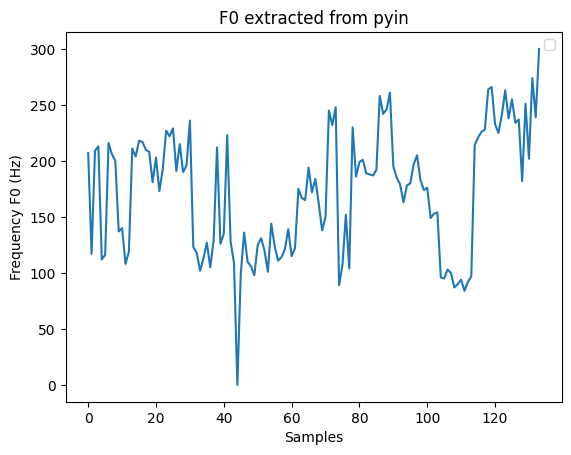

In [137]:
plt.plot(list(df_sorted["f0"].unique()))
plt.title("F0 extracted from pyin")
plt.xlabel("Samples")
plt.ylabel("Frequency F0 (Hz)")
plt.legend()
plt.show()

In [126]:
df_F = df[df["genders"] == "F"].reset_index(drop=True)
df_M = df[df["genders"] == "M"].reset_index(drop=True)

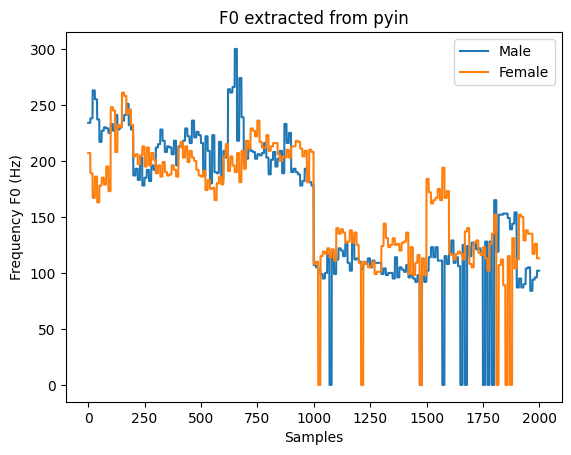

In [128]:
plt.plot(df_M["f0"], label="Male")
plt.plot(df_F["f0"], label="Female")
plt.title("F0 extracted from pyin")
plt.xlabel("Samples")
plt.ylabel("Frequency F0 (Hz)")
plt.legend()
plt.show()

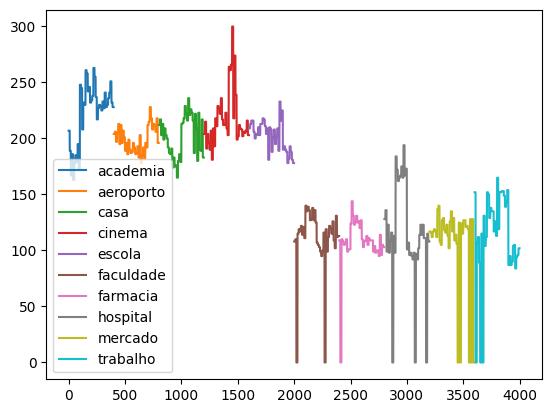

In [161]:
labels = list(df['words'].unique())
for label in labels:
    df_label = df[df['words'] == label]
    plt.plot(df_label["f0"], label=f"{label}")
plt.legend()
plt.show()

In [ ]:
A variação de pitch está mais ligada a palavra do que ao gênero do falante. 
Quando por medir o viés entre o treino e teste, precisa verificar se a distribuição de palavras é similar entre os conjuntos. Não somente os gêneros. 

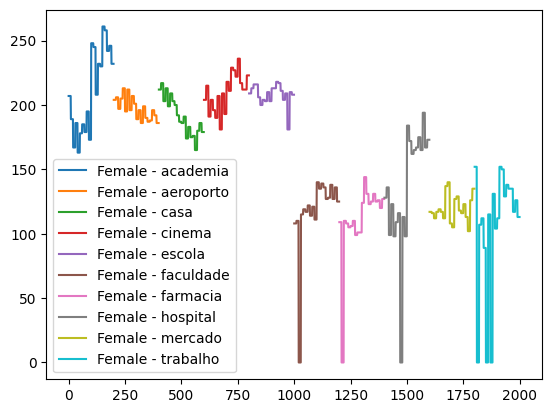

In [131]:
labels = list(df_F['words'].unique())
for label in labels:
    df_F_label = df_F[df_F['words'] == label]
    plt.plot(df_F_label["f0"], label=f"Female - {label}")
plt.legend()
plt.show()

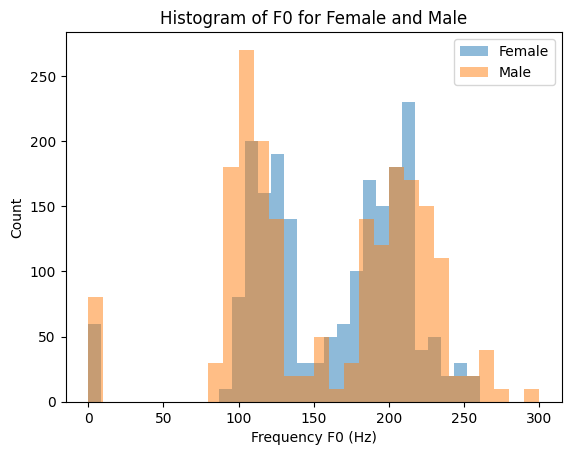

In [138]:
plt.hist(df_F["f0"], bins=30, alpha=0.5, label="Female")
plt.hist(df_M["f0"], bins=30, alpha=0.5, label="Male")
plt.title("Histogram of F0 for Female and Male")
plt.xlabel("Frequency F0 (Hz)")
plt.ylabel("Count")
plt.legend()

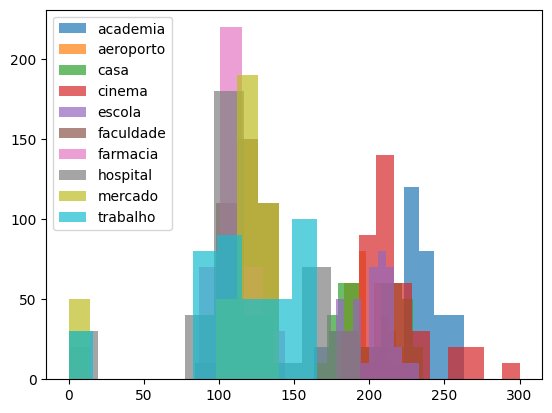

In [160]:
labels = list(df['words'].unique())
for label in labels:
    df_label = df[df['words'] == label]
    plt.hist(df_label["f0"], label=f"{label}", alpha=0.7)
plt.legend()
plt.show()

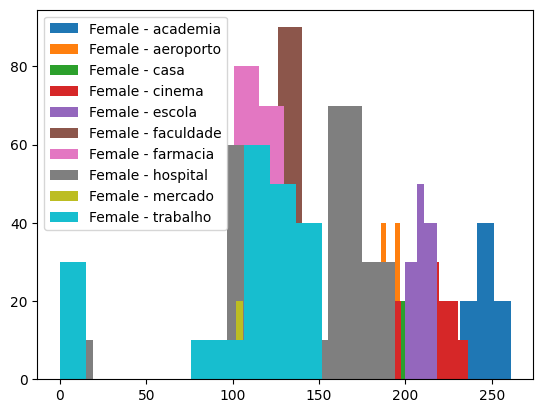

In [139]:
labels = list(df_F['words'].unique())
for label in labels:
    df_F_label = df_F[df_F['words'] == label]
    plt.hist(df_F_label["f0"], label=f"Female - {label}")
plt.legend()
plt.show()

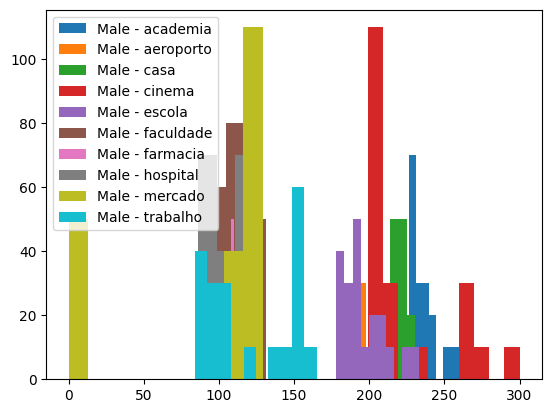

In [143]:
labels = list(df_M['words'].unique())
for label in labels:
    df_M_label = df_M[df_M['words'] == label]
    plt.hist(df_M_label["f0"], label=f"Male - {label}")
plt.legend()
plt.show()

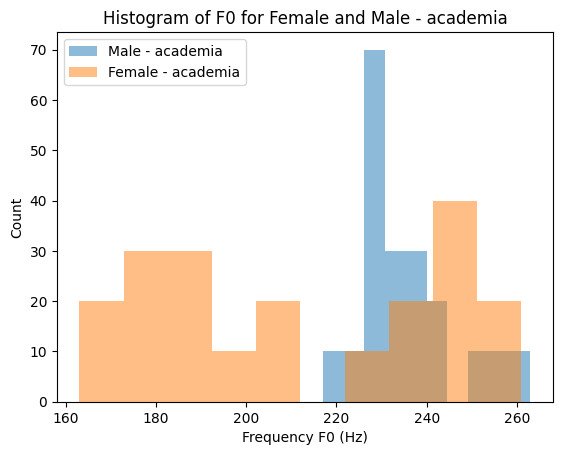

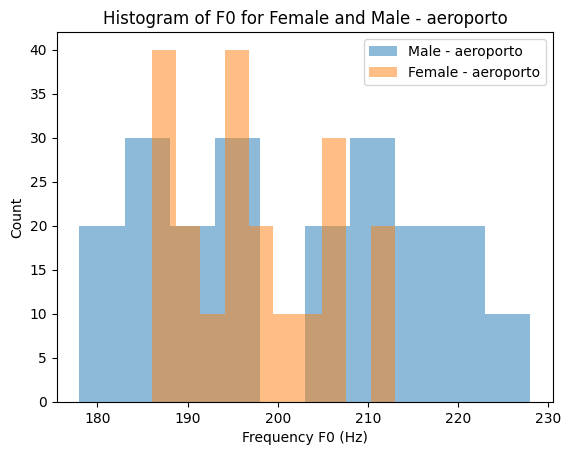

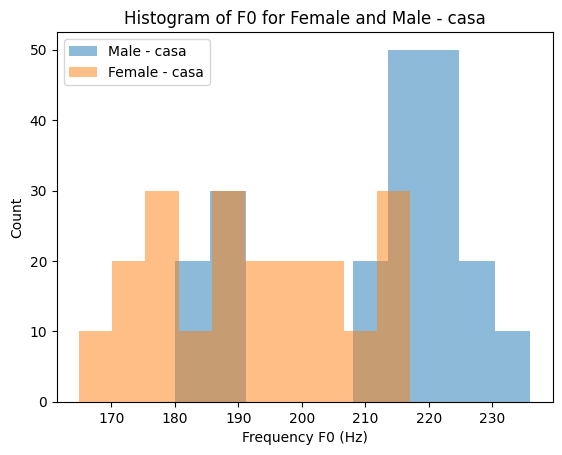

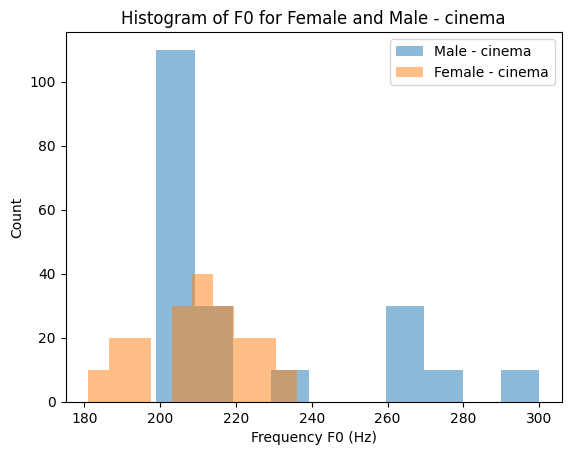

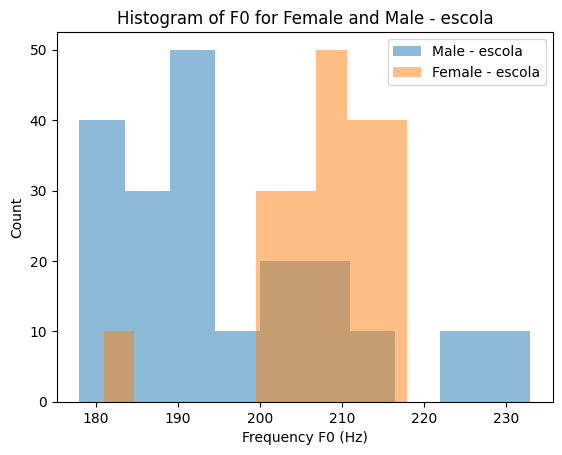

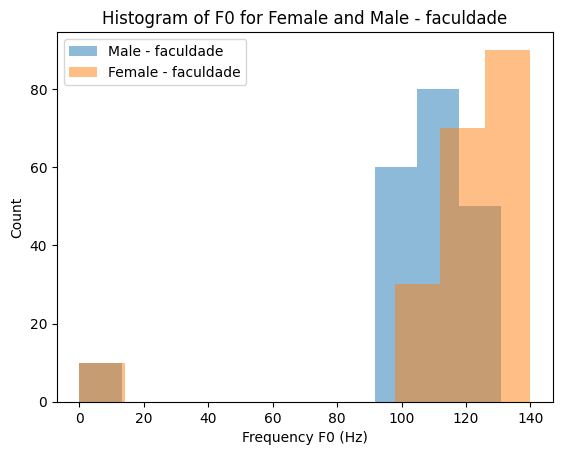

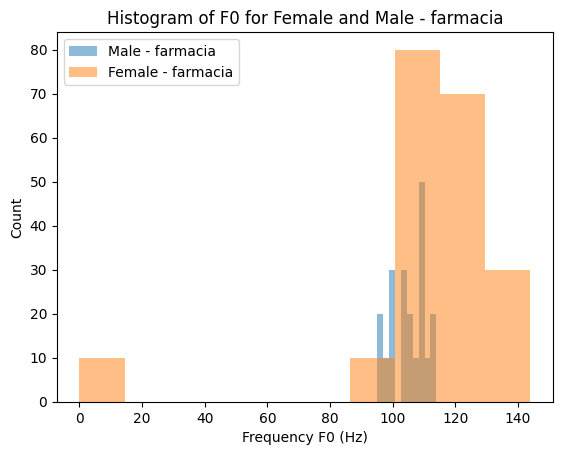

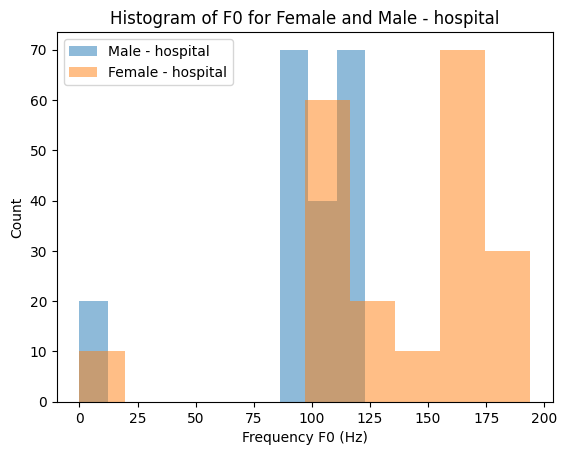

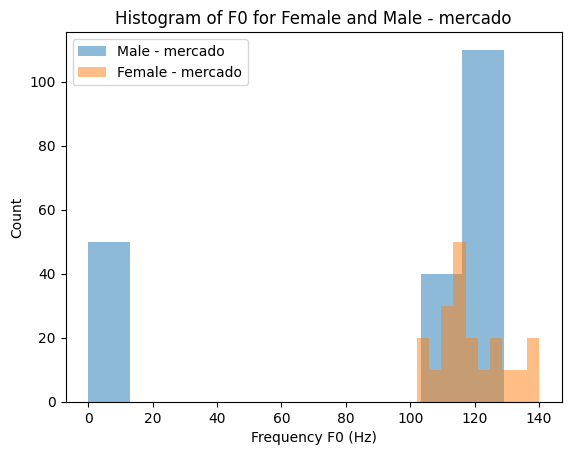

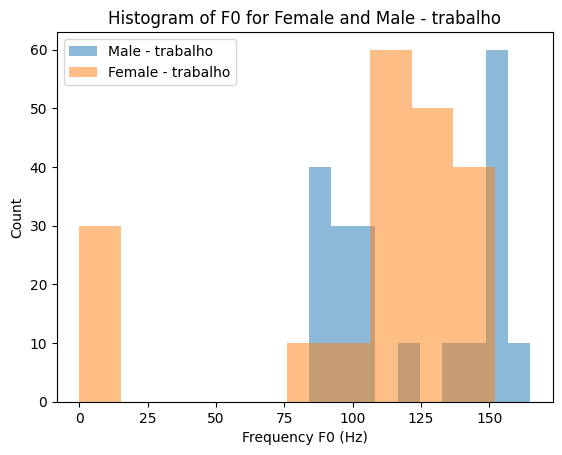

In [142]:
labels = list(df_F['words'].unique())
for label in labels:
    df_F_label = df_F[df_F['words'] == label]
    df_M_label = df_M[df_M['words'] == label]
    plt.hist(df_M_label["f0"], label=f"Male - {label}", alpha=0.5)
    plt.hist(df_F_label["f0"], label=f"Female - {label}", alpha=0.5)
    plt.title(f"Histogram of F0 for Female and Male - {label}")
    plt.xlabel("Frequency F0 (Hz)")
    plt.ylabel("Count")
    plt.legend()
    plt.show()

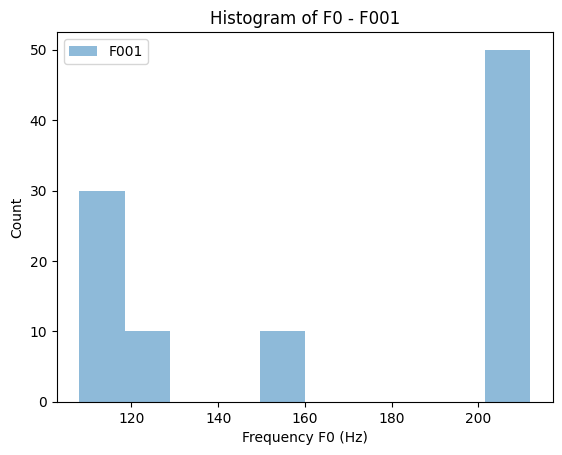

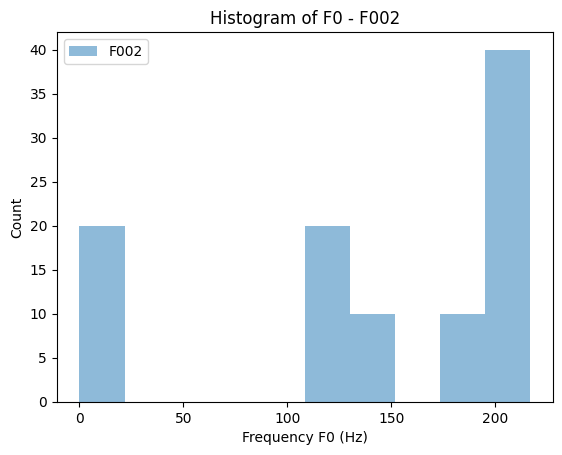

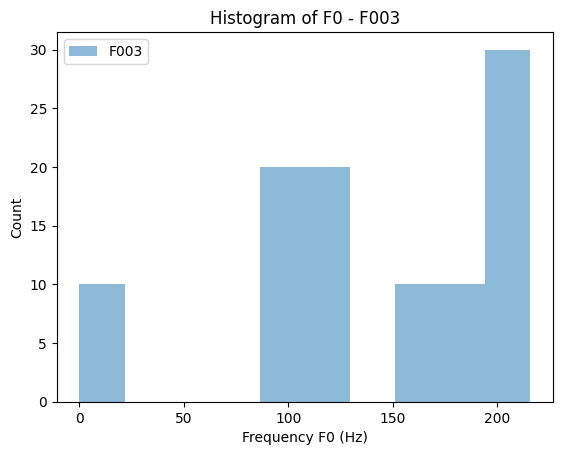

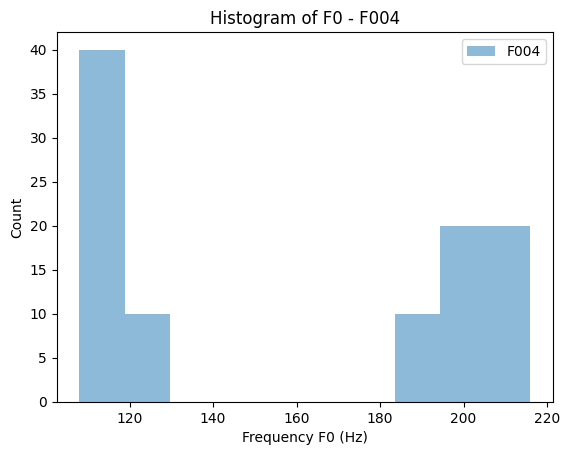

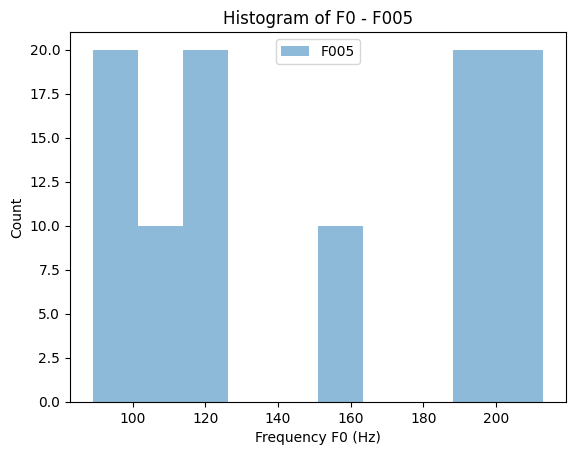

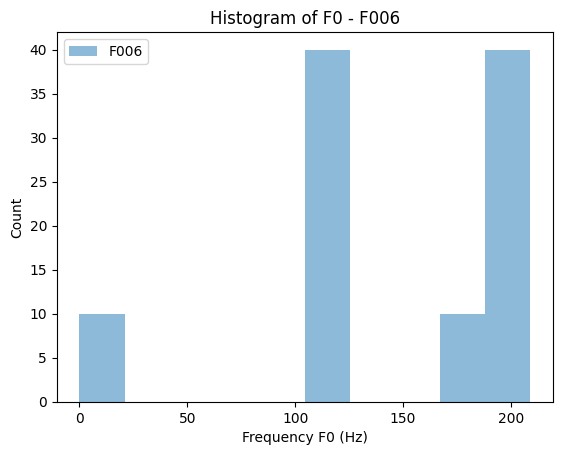

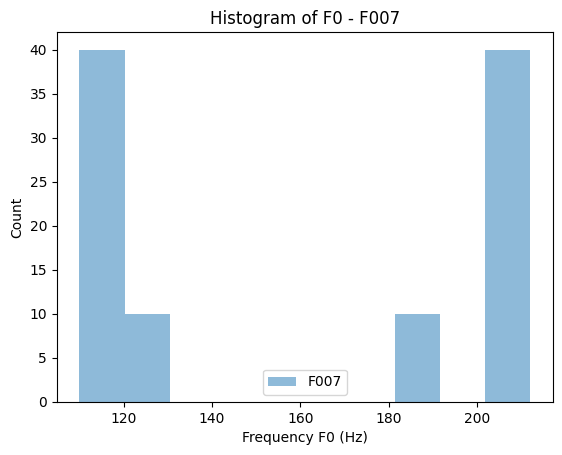

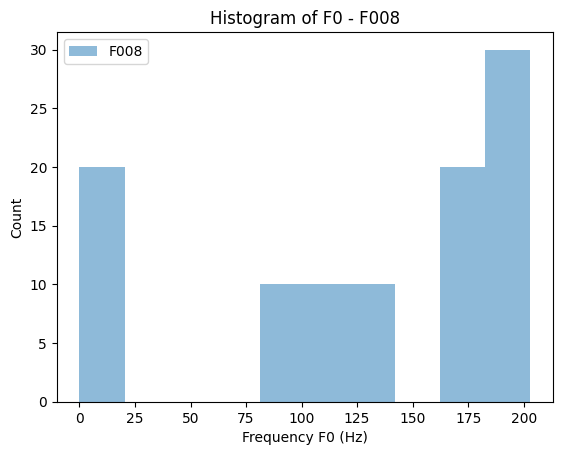

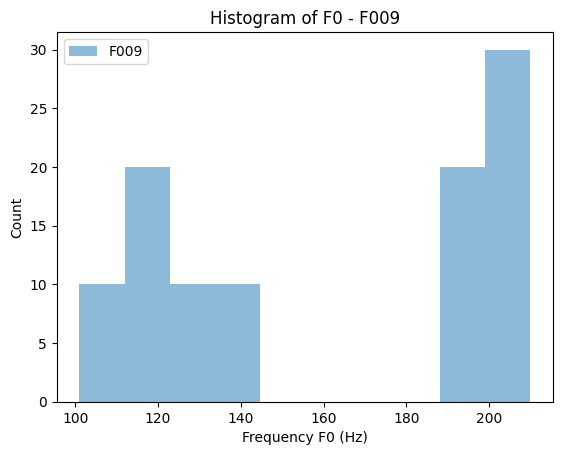

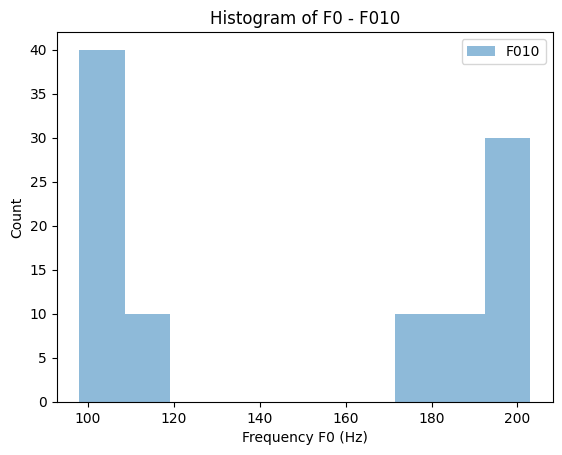

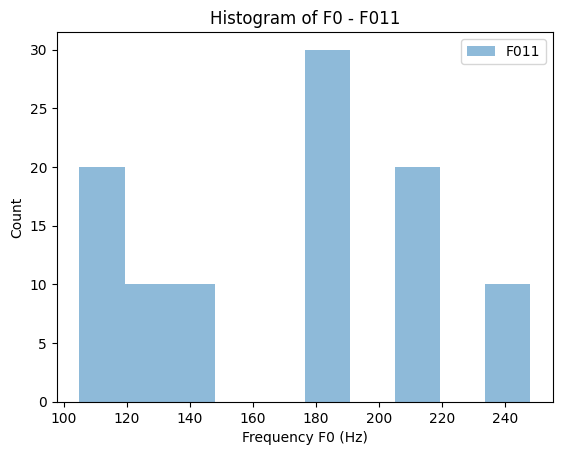

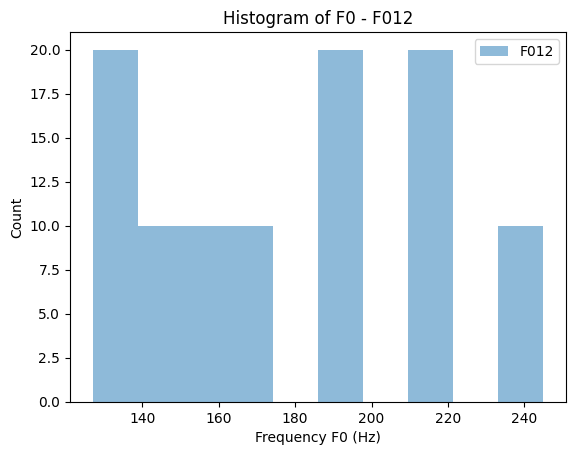

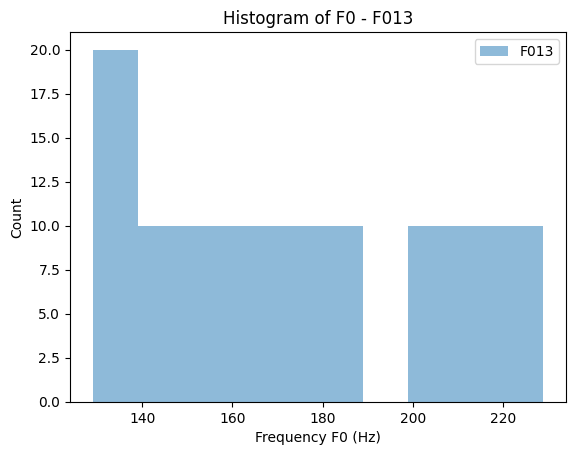

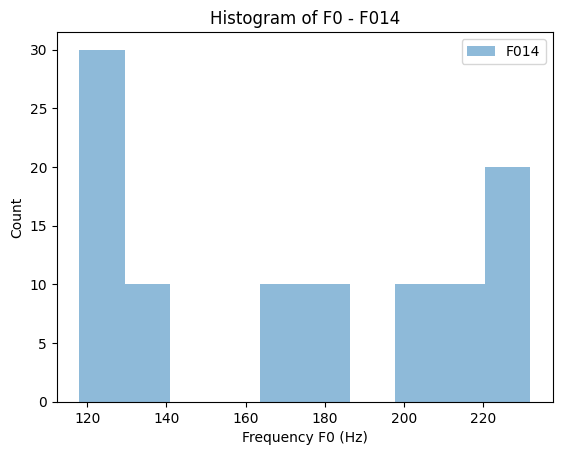

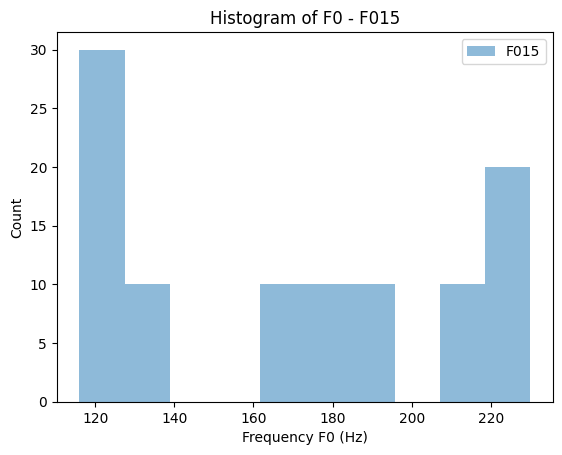

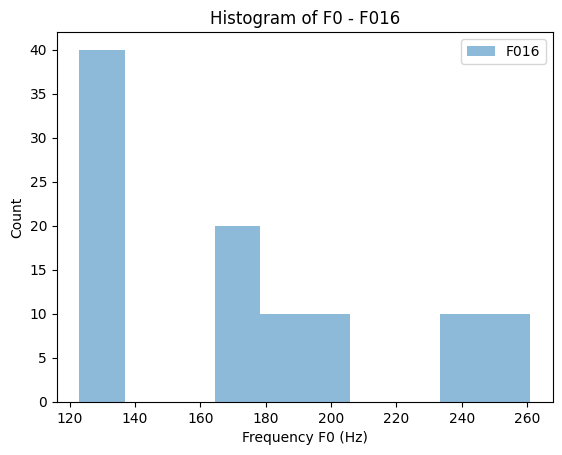

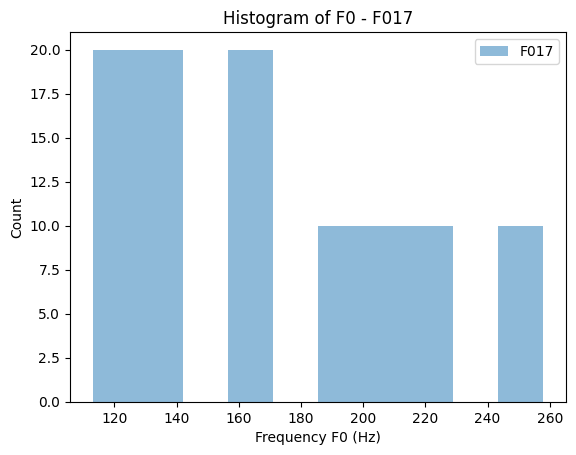

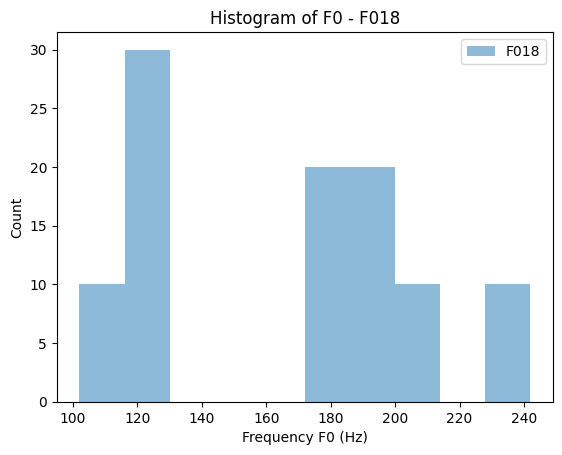

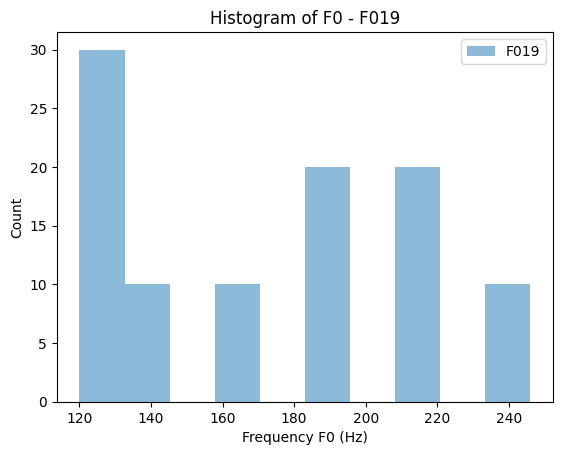

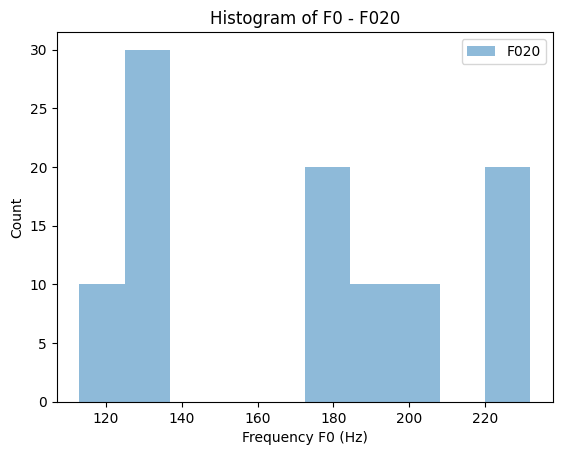

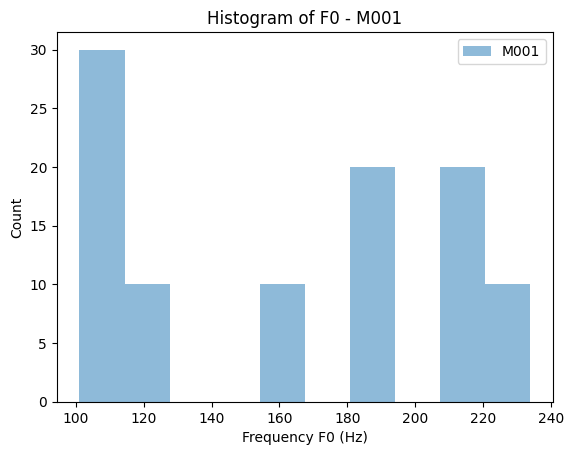

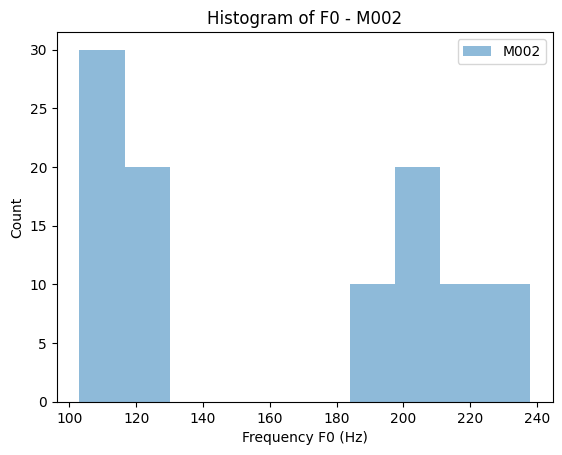

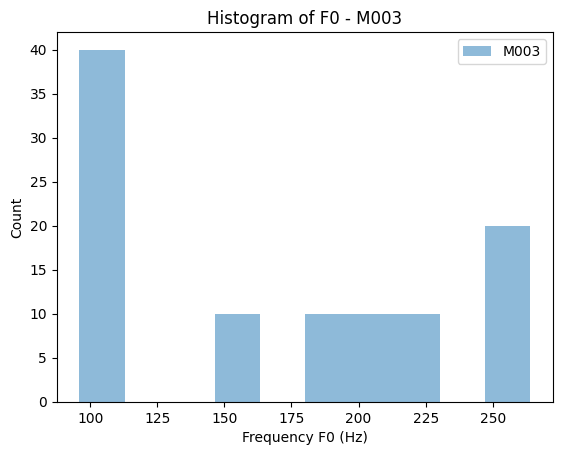

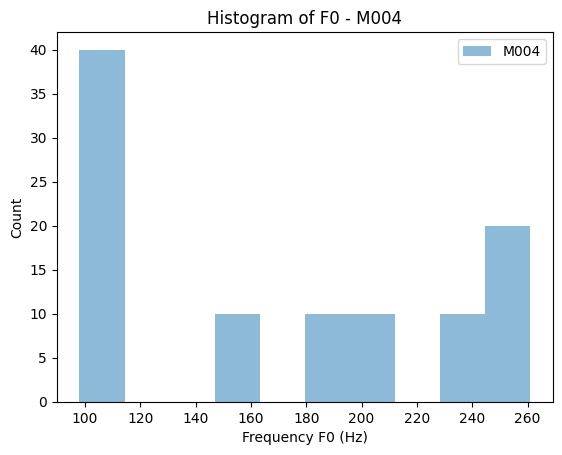

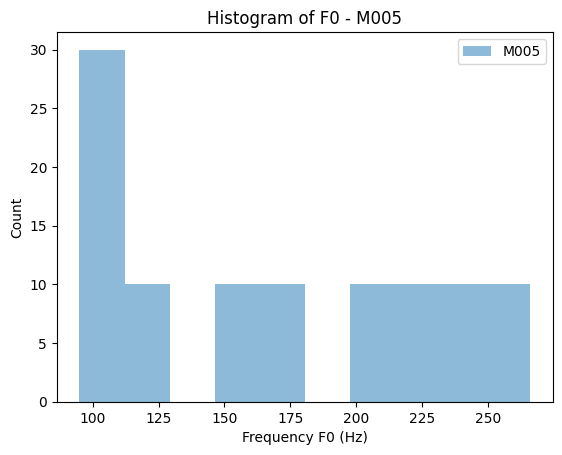

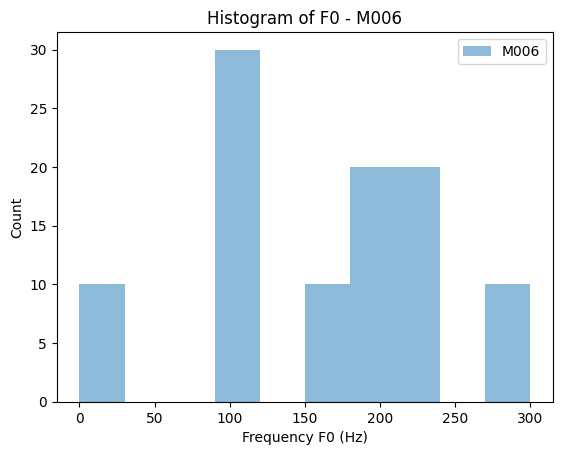

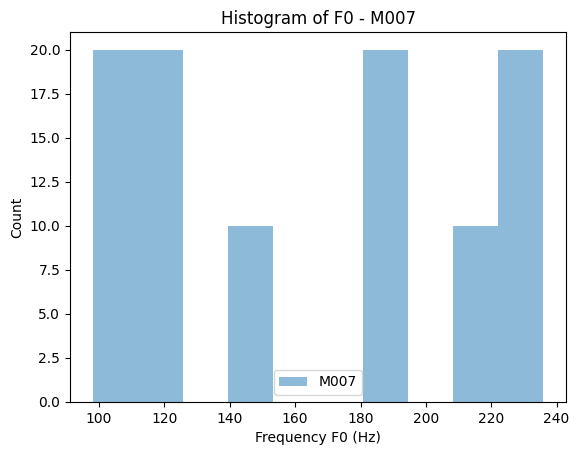

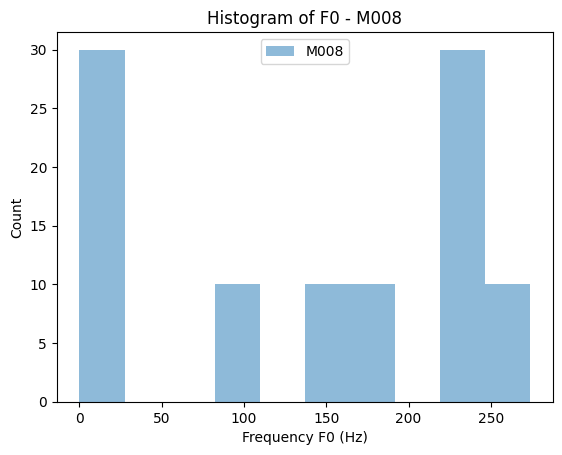

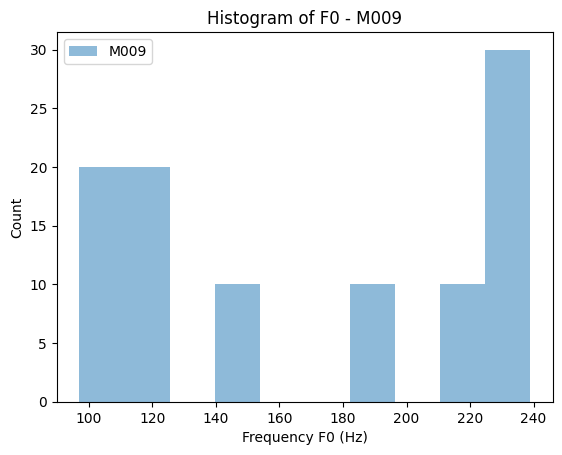

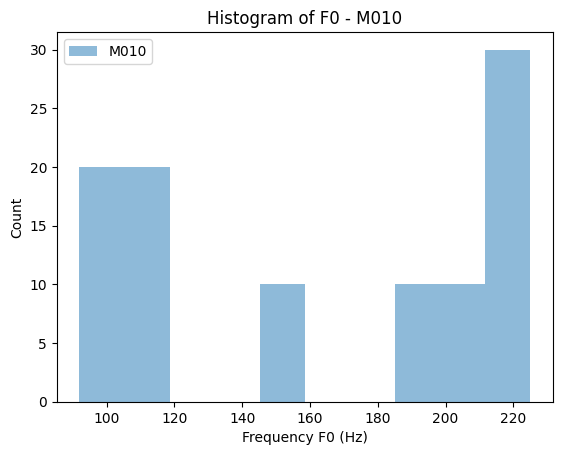

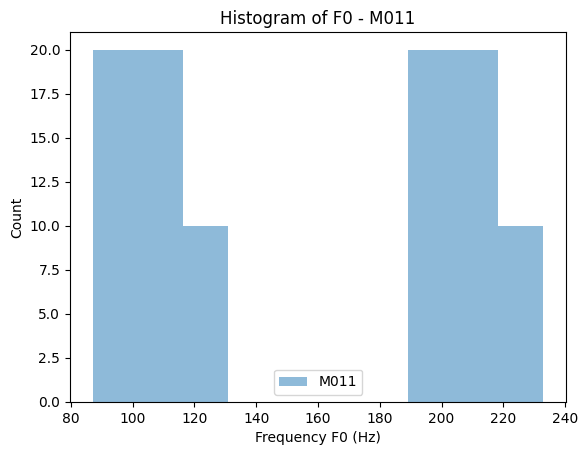

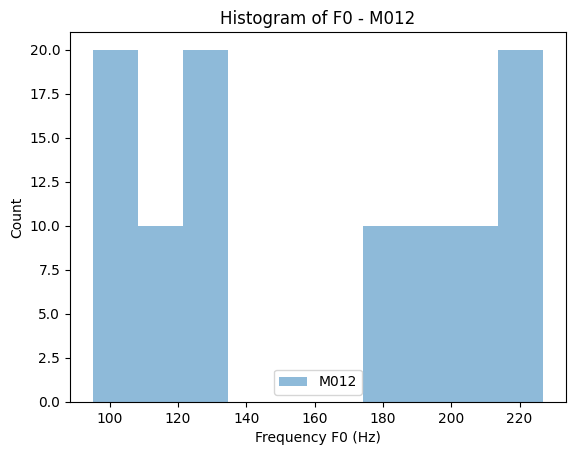

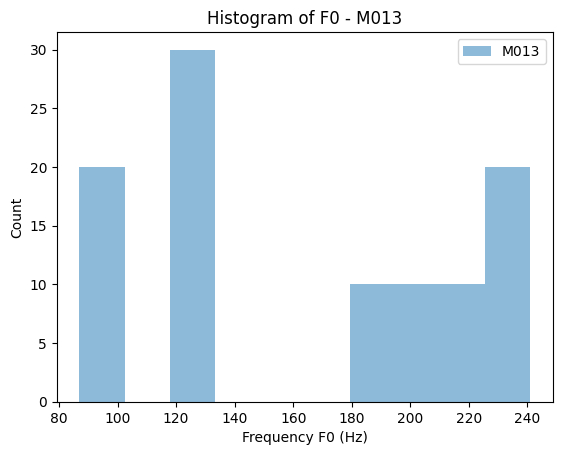

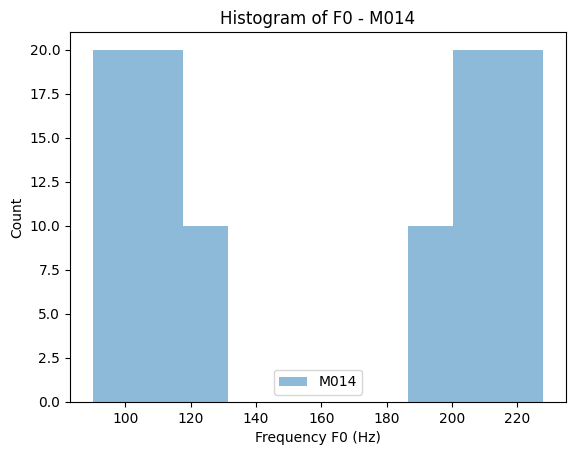

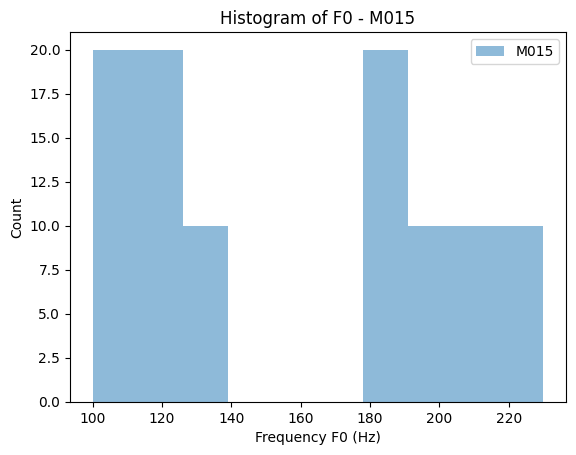

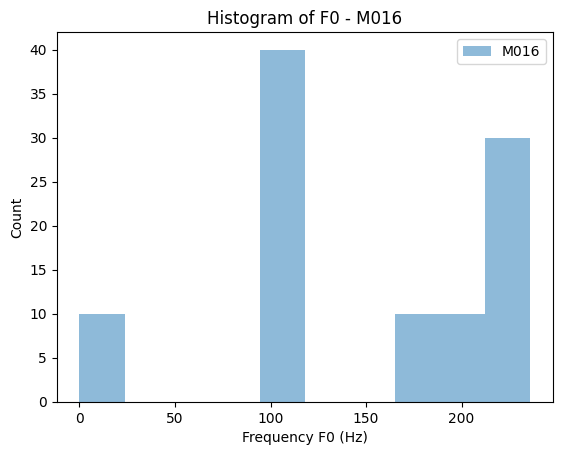

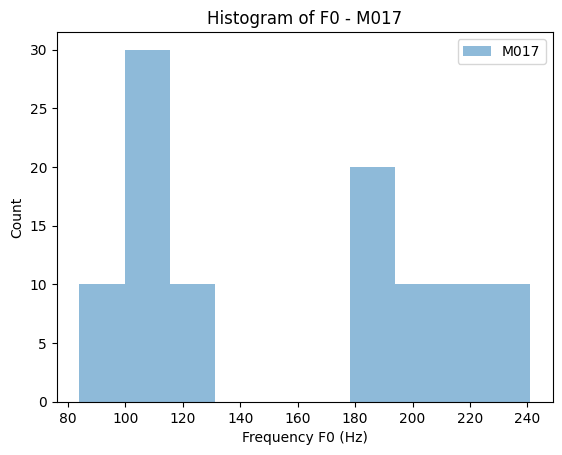

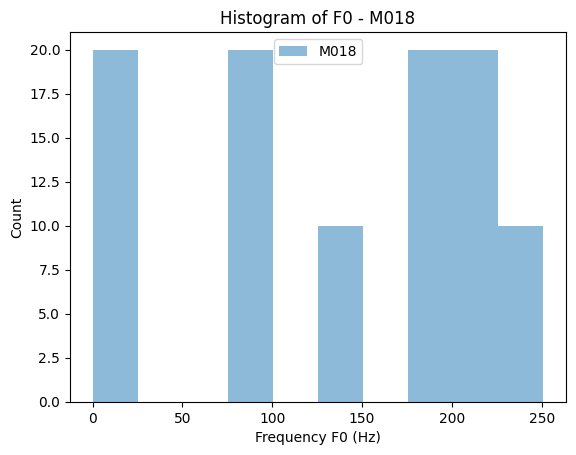

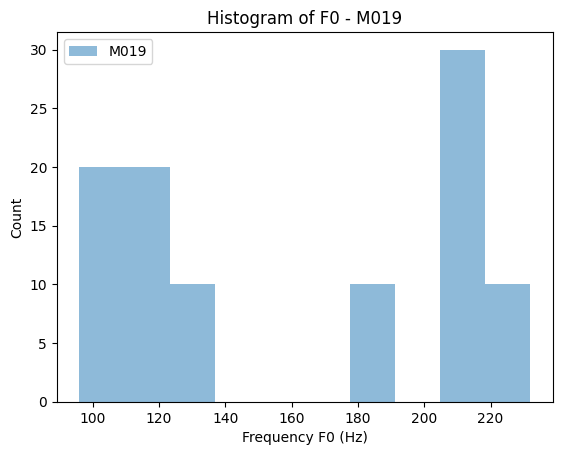

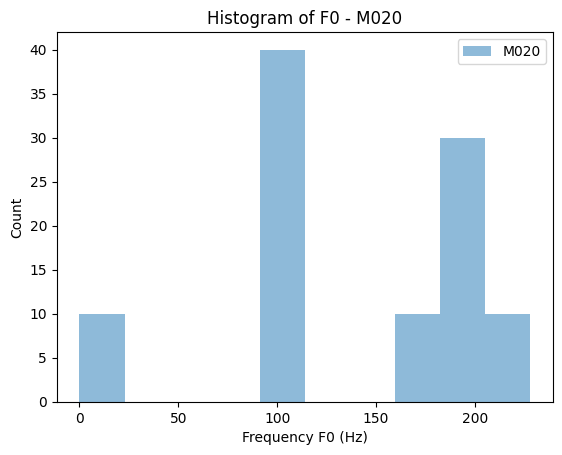

In [156]:
users = list(df['users'].unique())
for user in users:
    df_user = df[df['users'] == user]
    plt.hist(df_user["f0"], label=f"{user}", alpha=0.5)
    plt.title(f"Histogram of F0 - {user}")
    plt.xlabel("Frequency F0 (Hz)")
    plt.ylabel("Count")
    plt.legend()
    plt.show()

In [ ]:
users = list(df['users'].unique())
for user in users:
    df_F_user = df_F[df_F['users'] == user]
    df_M_user = df_M[df_M['users'] == user]
    plt.hist(df_M_user["f0"], label=f"Male - {user}", alpha=0.5)
    plt.hist(df_F_user["f0"], label=f"Female - {user}", alpha=0.5)
    plt.title(f"Histogram of F0 for Female and Male - {user}")
    plt.xlabel("Frequency F0 (Hz)")
    plt.ylabel("Count")
    plt.legend()
    plt.show()

### Setup 3.2- F0 - Crepe

In [ ]:
path = "../pitch/GPS_cmd_16k_renamed_jpynb_crepe_avg_by_word_user.csv"
df_raw = pd.read_csv(path)
df_c = df_raw.copy()
df_c["filepaths"] = df_c["filepaths"].apply(lambda x: x.replace("jovyan/work/OneDrive/Documentos/Doutorado/dataset", "ferreira/datasets"))
df_c

,filepaths,users,genders,words,f0
0,/home/ferreira/datasets/GPS_cmd_16k_renamed/ac...,F001,F,academia,198
1,/home/ferreira/datasets/GPS_cmd_16k_renamed/ac...,F001,F,academia,198
2,/home/ferreira/datasets/GPS_cmd_16k_renamed/ac...,F001,F,academia,198
3,/home/ferreira/datasets/GPS_cmd_16k_renamed/ac...,F001,F,academia,198
4,/home/ferreira/datasets/GPS_cmd_16k_renamed/ac...,F001,F,academia,198
...,...,...,...,...,...
3995,/home/ferreira/datasets/GPS_cmd_16k_renamed/tr...,M020,M,trabalho,88
3996,/home/ferreira/datasets/GPS_cmd_16k_renamed/tr...,M020,M,trabalho,88
3997,/home/ferreira/datasets/GPS_cmd_16k_renamed/tr...,M020,M,trabalho,88
3998,/home/ferreira/datasets/GPS_cmd_16k_renamed/tr...,M020,M,trabalho,88


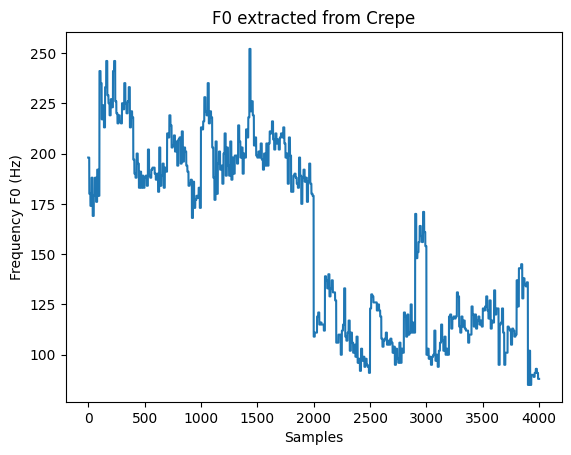

In [154]:
plt.plot(df_c["f0"])
plt.title("F0 extracted from Crepe")
plt.xlabel("Samples")
plt.ylabel("Frequency F0 (Hz)")
plt.show()

In [144]:
df_c_F = df_c[df_c["genders"] == "F"].reset_index(drop=True)
df_c_M = df_c[df_c["genders"] == "M"].reset_index(drop=True)

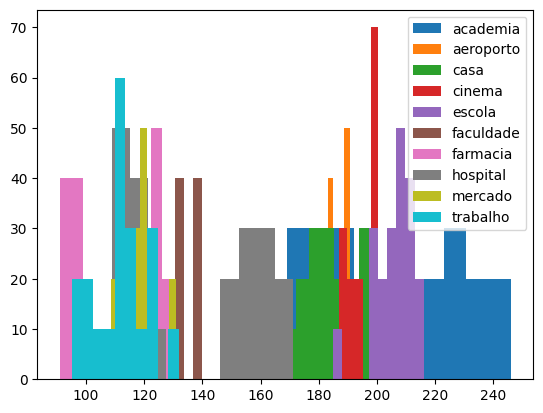

In [148]:
labels = list(df_c_F['words'].unique())
for label in labels:
    df_c_F_label = df_c_F[df_c_F['words'] == label]
    plt.hist(df_c_F_label["f0"], label=f"{label}")
plt.legend()
plt.show()

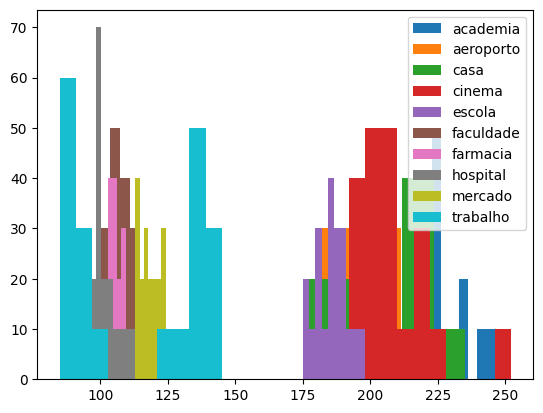

In [147]:
labels = list(df_c_M['words'].unique())
for label in labels:
    df_c_M_label = df_c_M[df_c_M['words'] == label]
    plt.hist(df_c_M_label["f0"], label=f"{label}")
plt.legend()
plt.show()

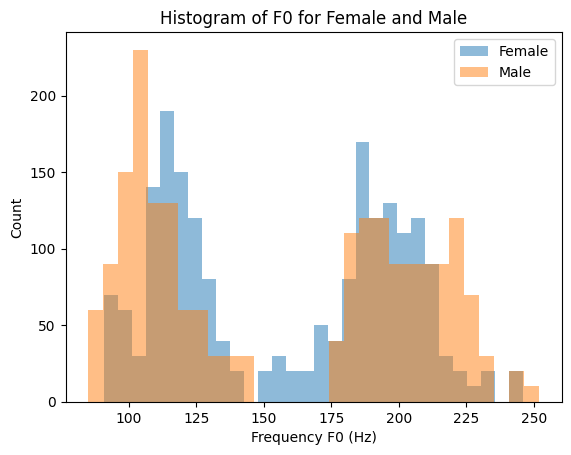

In [149]:
plt.hist(df_c_F["f0"], bins=30, alpha=0.5, label="Female")
plt.hist(df_c_M["f0"], bins=30, alpha=0.5, label="Male")
plt.title("Histogram of F0 for Female and Male")
plt.xlabel("Frequency F0 (Hz)")
plt.ylabel("Count")
plt.legend()

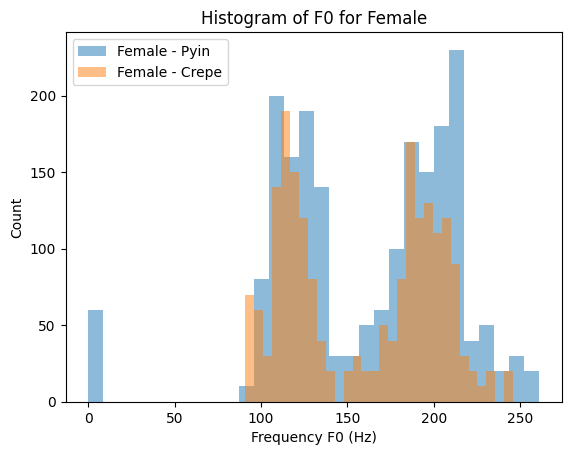

In [152]:
plt.hist(df_F["f0"], bins=30, alpha=0.5, label="Female - Pyin")
plt.hist(df_c_F["f0"], bins=30, alpha=0.5, label="Female - Crepe")
plt.title("Histogram of F0 for Female")
plt.xlabel("Frequency F0 (Hz)")
plt.ylabel("Count")
plt.legend()

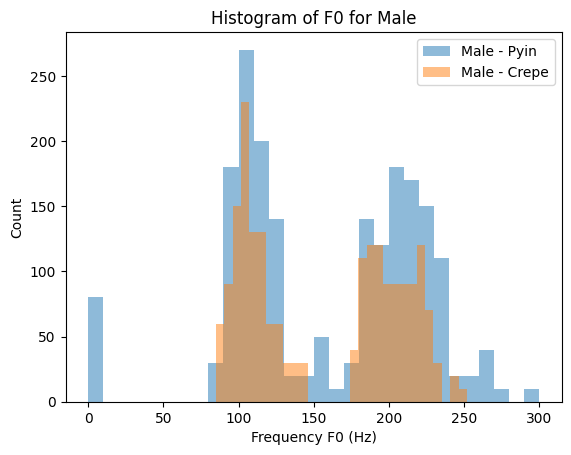

In [153]:
plt.hist(df_M["f0"], bins=30, alpha=0.5, label="Male - Pyin")
plt.hist(df_c_M["f0"], bins=30, alpha=0.5, label="Male - Crepe")
plt.title("Histogram of F0 for Male")
plt.xlabel("Frequency F0 (Hz)")
plt.ylabel("Count")
plt.legend()